In [1]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../GPs.jl")
include("../functions.jl")
include("../myfuncs.jl")
include("../integrators.jl")
include("../util_shoji.jl")


simulate_pf_selforg (generic function with 1 method)

Maximum error = 0.0008084398633819954
L2 error       = 0.000601071860383032


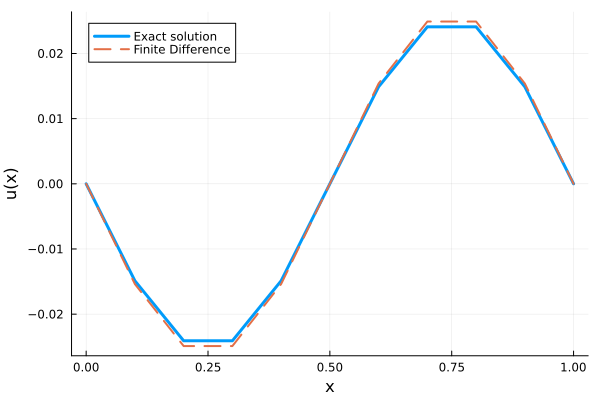

In [2]:
using LinearAlgebra
using Plots

# -----------------------------
# Problem setting
# -----------------------------

dt = 0.1
T = 1.0
x = 0:dt:T


xi = x[2:end-1]
n = length(xi)

# -----------------------------
# Construct finite difference matrix
# -u'' = f
# -----------------------------
A = zeros(n, n)

for i in 1:n
    A[i,i] = 2.0
    if i > 1
        A[i,i-1] = -1.0
    end
    if i < n
        A[i,i+1] = -1.0
    end
end

A ./= (dt)^2

# Right-hand side
f = -sin.(2π .* xi)

# Solve linear system
u_interior = A \ f

# Include boundary values
u_num = vcat(0.0, u_interior, 0.0)

# -----------------------------
# Exact solution
# -----------------------------
u_exact_vec = -(1/(2π)^2) .* sin.(2π .* x)

# -----------------------------
# Error
# -----------------------------
max_error = maximum(abs.(u_num .- u_exact_vec))
l2_error = sqrt(sum((u_num .- u_exact_vec).^2) * (dt))

println("Maximum error = ", max_error)
println("L2 error       = ", l2_error)

# -----------------------------
# Plot
# -----------------------------
plot(x, u_exact_vec,
    lw=3,
    label="Exact solution",
    xlabel="x",
    ylabel="u(x)")

plot!(x, u_num,
    linestyle=:dash,
    lw=2,
    label="Finite Difference")

In [23]:
ℓ =10.0
σf =10.0
prior_mean = 0.0
#obs_noise = dt^4

x_all = collect(dt:dt:1-dt)
n = length(x_all)
X_test =
    collect(
        range(
            0.0,
            1.0,
            length=500
        )
    )


println("x_all.size:", x_all.size)
println("n:", n)
println("X_test:", X_test.size)
Ktest = kernel_matrix(X_test, x_all)

function laplacian_matrix(n, dt)

    D = zeros(n,n)

    for i in 1:n

        D[i,i] = -2

        if i > 1
            D[i,i-1] = 1
        end

        if i < n
            D[i,i+1] = 1
        end

    end

    D ./= dt^2

    return D
end


Kuu = kernel_matrix(
    x_all,
    x_all;
    ℓ=ℓ,
    σf=σf
)

D = laplacian_matrix(length(x_all) , dt)
println("D.size:", D.size)

KLL = D * Kuu * D'

KuL = Kuu * D'

KLu = D * Kuu

println("KLL.size:", KLL.size)

println("KuL.size:", KuL.size)

println("KLu.size:", KLu.size)


k0 = reshape(
    kernel_matrix([0.0], x_all; ℓ=ℓ, σf=σf),
    1, :
)

k1 = reshape(
    kernel_matrix([1.0], x_all; ℓ=ℓ, σf=σf),
    1, :
)

println("k0:", k0.size)
println("k1:", k1.size)

H = [
    k0
    D
    k1
]

Kobs = H * Kuu * H'

Ks = Ktest * H'

K0 = k0
K1 = k1
K0L = k0 * D'
K1L = k1 * D'

Kobs = [
    kernel_matrix([0.0],[0.0])   k0               kernel_matrix([0.0],[1.0])
    k0'                          KLL              k1'
    kernel_matrix([1.0],[0.0])   k1               kernel_matrix([1.0],[1.0])
]

Ks = [
    kernel_matrix(X_test, [0.0])   Ktest * D'   kernel_matrix(X_test, [1.0])
]

x_all.size:(9,)
n:9
X_test:(500,)
D.size:(9, 9)
KLL.size:(9, 9)
KuL.size:(9, 9)
KLu.size:(9, 9)
k0:(1, 9)
k1:(1, 9)


500×11 Matrix{Float64}:
 1.0       -100.983   -0.938739  -0.867994  …  -0.261673   -60.7805  0.606531
 0.999998  -100.983   -0.939891  -0.869655     -0.264412   -60.9046  0.607746
 0.999992  -100.983   -0.941033  -0.871307     -0.267152   -61.0288  0.608962
 0.999982  -100.983   -0.942164  -0.872949     -0.269894   -61.153   0.610177
 0.999968  -100.982   -0.943284  -0.874582     -0.272637   -61.2772  0.611393
 0.99995   -100.98    -0.944393  -0.876205  …  -0.275381   -61.4014  0.612608
 0.999928  -100.979   -0.945492  -0.877818     -0.278125   -61.5255  0.613823
 0.999902  -100.977   -0.946579  -0.879422     -0.280871   -61.6497  0.615039
 0.999871  -100.974   -0.947655  -0.881016     -0.283618   -61.7739  0.616254
 0.999837  -100.971   -0.94872   -0.8826       -0.286366   -61.898   0.617469
 ⋮                                          ⋱                        ⋮
 0.616254   -61.7739  -0.283618  -0.42092      -0.947655  -100.974   0.999871
 0.615039   -61.6497  -0.280871  -0.418182     

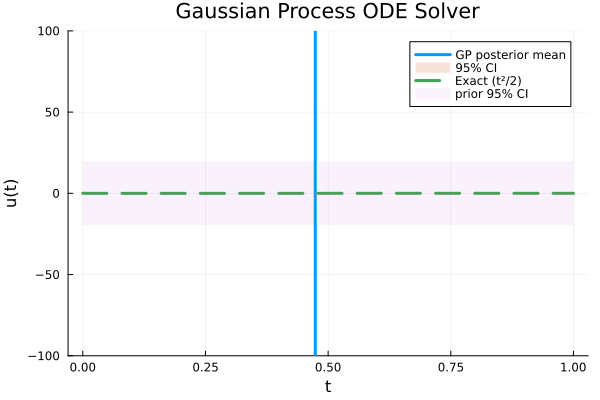

"/Users/shoji/Project_with_Jon/Poisson Equation/a.png"

In [24]:
m_y = vcat([prior_mean],  zeros(length(x_all)), [prior_mean])
m_x = fill(prior_mean, length(X_test))

rhs = -sin.(2π .* x_all)
y = vcat(
    [0.0],        # u(0)
    rhs,          # Δu
    [0.0]         # u(1)
)

Kss = kernel_matrix(
    X_test,
    X_test;
    ℓ=ℓ,
    σf=σf
)

μ =  Ks * (Kobs \ (y ))

Σ = Kss - Ks * (Kobs \ Ks')


std =
    sqrt.(max.(diag(Σ),0))

# =====================================================
# Exact solution
# =====================================================



u_exact(t) = -(1/(2π)^2) * sin(2π * t)


# =====================================================
# Plot
# =====================================================

plot(
    X_test,
    μ,
    lw=3,
    label="GP posterior mean"
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=
        μ .- 1.96 .* std,
    fillalpha=0.2,
    linealpha=0,
    label="95% CI"
)

plot!(
    X_test,
    u_exact.(X_test),
    lw=3,
    ls=:dash,
    label="Exact (t²/2)"
)

μ_prior = zeros(length(X_test))



std_prior = sqrt.(diag(Kss))


μ_prior = fill(prior_mean, length(X_test))

plot!(
    X_test,
    ylims = (-100, 100),
    μ_prior .+ 1.96 .* std_prior,
    fillrange = μ_prior .- 1.96 .* std_prior,
    fillalpha = 0.1,
    linealpha = 0,
    label = "prior 95% CI"
)

xlabel!("t")
ylabel!("u(t)")
title!("Gaussian Process ODE Solver")

display(current())

savefig("a.png")